# Training and retraining analytics

This notebook analyzes clean-test results for a Vision Transformer trained on GTSRB. It separates the immediate effect of attention/MLP pruning from recovery after retraining, and compares retraining from the original initialization with random reinitialization.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {'attention': '#2563eb', 'mlp': '#d97706', 'original_init': '#1f2937', 'random_reinit': '#059669'}

def find_repo_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / 'results' / 'training_results.csv').exists():
            return candidate
    raise FileNotFoundError('Could not find results/training_results.csv. Run from this repository or its notebooks directory.')

ROOT = find_repo_root()
results = pd.read_csv(ROOT / 'results' / 'training_results.csv')
results['pruning_pct'] = results['requested_ratio'] * 100
results['accuracy_pct'] = results['test_accuracy'] * 100
results['f1_pct'] = results['test_f1'] * 100
results['sparsity_pct'] = results['effective_parameter_sparsity'] * 100
dense_accuracy = results.loc[results['run_type'].eq('dense'), 'accuracy_pct'].iloc[0]
print(f'Dense baseline accuracy: {dense_accuracy:.2f}%')
print(results['run_type'].value_counts().to_string())

Dense baseline accuracy: 94.44%
run_type
retraining            16
pruning_evaluation     8
dense                  1


In [2]:
# Create a condition-level table used by the rest of the notebook.
pruned = results.query("run_type == 'pruning_evaluation'").copy()
retrained = results.query("run_type == 'retraining'").copy()

baseline_cols = ['prune_type', 'requested_ratio', 'accuracy_pct']
pruned_reference = pruned[baseline_cols].rename(columns={'accuracy_pct': 'pruned_accuracy_pct'})
retrained = retrained.merge(pruned_reference, on=['prune_type', 'requested_ratio'], validate='many_to_one')
retrained['recovery_pp'] = retrained['accuracy_pct'] - retrained['pruned_accuracy_pct']
retrained['vs_dense_pp'] = retrained['accuracy_pct'] - dense_accuracy

summary = retrained[['prune_type', 'pruning_pct', 'init_method', 'accuracy_pct', 'pruned_accuracy_pct', 'recovery_pp', 'vs_dense_pp', 'sparsity_pct', 'training_seconds', 'best_epoch', 'early_stopped']].sort_values(['prune_type', 'pruning_pct', 'init_method'])
summary.round(2)

,prune_type,pruning_pct,init_method,accuracy_pct,pruned_accuracy_pct,recovery_pp,vs_dense_pp,sparsity_pct,training_seconds,best_epoch,early_stopped
1,attention,20.0,original_init,94.87,94.26,0.61,0.43,6.55,2959.37,70.0,1.0
0,attention,20.0,random_reinit,93.78,94.26,-0.48,-0.66,6.55,2963.88,72.0,0.0
2,attention,40.0,original_init,94.96,91.88,3.07,0.51,13.10,2684.32,74.0,0.0
3,attention,40.0,random_reinit,90.86,91.88,-1.03,-3.59,13.10,2685.36,70.0,1.0
4,attention,60.0,original_init,95.01,71.50,23.52,0.57,19.65,2857.20,73.0,0.0
5,attention,60.0,random_reinit,90.99,71.50,19.49,-3.45,19.65,2855.40,74.0,0.0
6,attention,80.0,original_init,93.38,0.83,92.55,-1.06,26.20,2859.30,74.0,0.0
7,attention,80.0,random_reinit,83.86,0.83,83.03,-10.58,26.20,2872.08,75.0,0.0
8,mlp,20.0,original_init,94.84,94.28,0.55,0.40,13.06,2898.02,77.0,0.0
9,mlp,20.0,random_reinit,93.50,94.28,-0.78,-0.94,13.06,2899.86,77.0,0.0


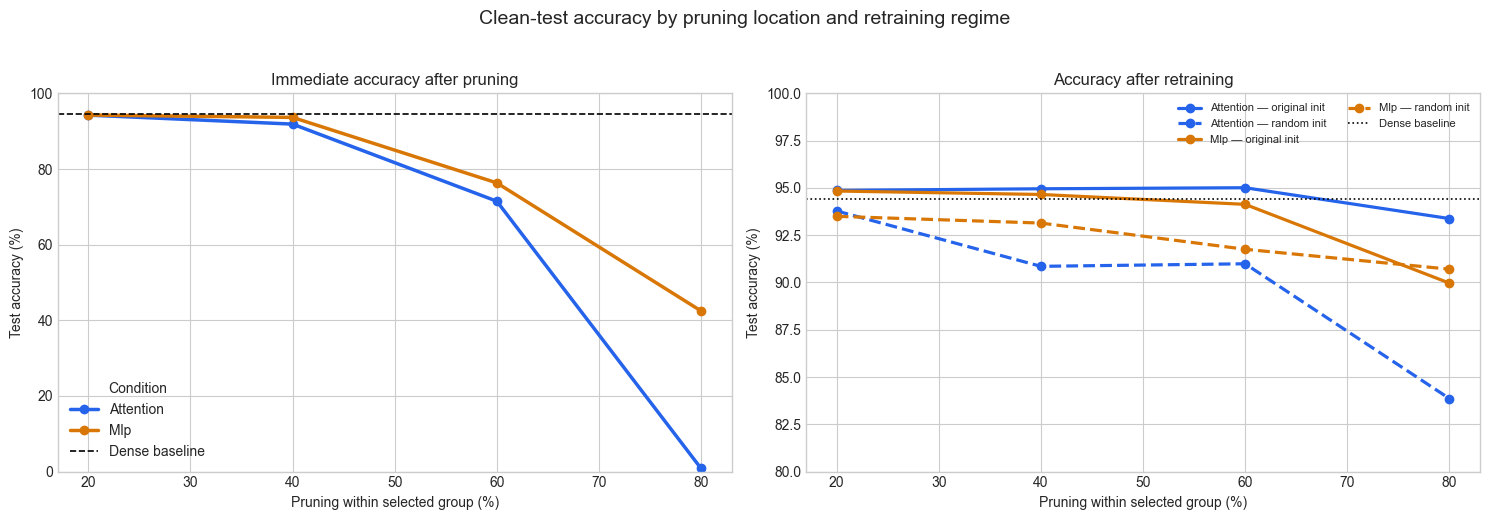

In [3]:
# 1. Immediate pruning damage and retraining recovery.
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
for prune_type, group in pruned.groupby('prune_type'):
    axes[0].plot(group['pruning_pct'], group['accuracy_pct'], marker='o', linewidth=2.5, label=prune_type.title(), color=COLORS[prune_type])
axes[0].axhline(dense_accuracy, color='black', linestyle='--', linewidth=1.2, label='Dense baseline')
axes[0].set(title='Immediate accuracy after pruning', xlabel='Pruning within selected group (%)', ylabel='Test accuracy (%)', ylim=(0, 100))
axes[0].legend(title='Condition')

for (prune_type, init_method), group in retrained.groupby(['prune_type', 'init_method']):
    axes[1].plot(group['pruning_pct'], group['accuracy_pct'], marker='o', linewidth=2.3,
                 label=f"{prune_type.title()} — {'original' if init_method == 'original_init' else 'random'} init",
                 color=COLORS[prune_type], linestyle='-' if init_method == 'original_init' else '--')
axes[1].axhline(dense_accuracy, color='black', linestyle=':', linewidth=1.2, label='Dense baseline')
axes[1].set(title='Accuracy after retraining', xlabel='Pruning within selected group (%)', ylabel='Test accuracy (%)', ylim=(80, 100))
axes[1].legend(fontsize=8, ncol=2)
fig.suptitle('Clean-test accuracy by pruning location and retraining regime', y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

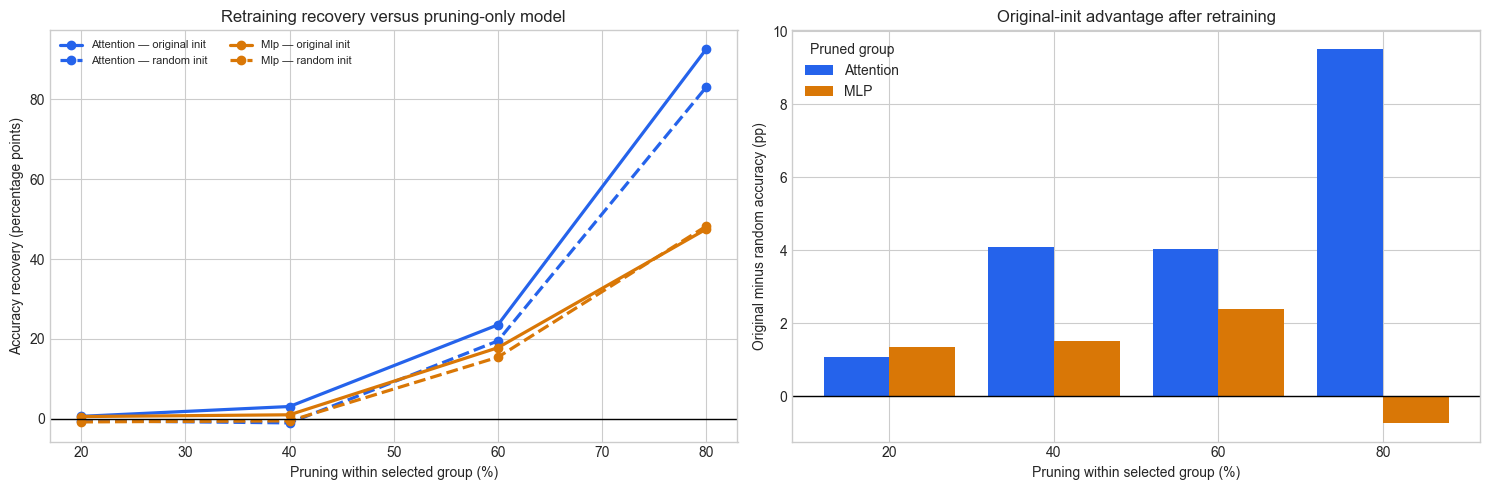

init_method,prune_type,pruning_pct,original_minus_random_pp
0,attention,20.0,1.08
1,attention,40.0,4.10
2,attention,60.0,4.02
3,attention,80.0,9.52
4,mlp,20.0,1.34
5,mlp,40.0,1.51
6,mlp,60.0,2.38
7,mlp,80.0,-0.74


In [4]:
# 2. Accuracy recovered by retraining and the benefit of retaining the original initialization.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for (prune_type, init_method), group in retrained.groupby(['prune_type', 'init_method']):
    axes[0].plot(group['pruning_pct'], group['recovery_pp'], marker='o', linewidth=2.3,
                 label=f"{prune_type.title()} — {'original' if init_method == 'original_init' else 'random'} init",
                 color=COLORS[prune_type], linestyle='-' if init_method == 'original_init' else '--')
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set(title='Retraining recovery versus pruning-only model', xlabel='Pruning within selected group (%)', ylabel='Accuracy recovery (percentage points)')
axes[0].legend(fontsize=8, ncol=2)

init_gap = retrained.pivot(index=['prune_type', 'pruning_pct'], columns='init_method', values='accuracy_pct').reset_index()
init_gap['original_minus_random_pp'] = init_gap['original_init'] - init_gap['random_reinit']
gap_plot = init_gap.pivot(index='pruning_pct', columns='prune_type', values='original_minus_random_pp').sort_index()
x = range(len(gap_plot))
axes[1].bar([v - 0.2 for v in x], gap_plot['attention'], width=0.4, color=COLORS['attention'], label='Attention')
axes[1].bar([v + 0.2 for v in x], gap_plot['mlp'], width=0.4, color=COLORS['mlp'], label='MLP')
axes[1].set_xticks(list(x), [f'{v:.0f}' for v in gap_plot.index])
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set(title='Original-init advantage after retraining', xlabel='Pruning within selected group (%)', ylabel='Original minus random accuracy (pp)')
axes[1].legend(title='Pruned group')
plt.tight_layout()
plt.show()

init_gap[['prune_type', 'pruning_pct', 'original_minus_random_pp']].round(2)

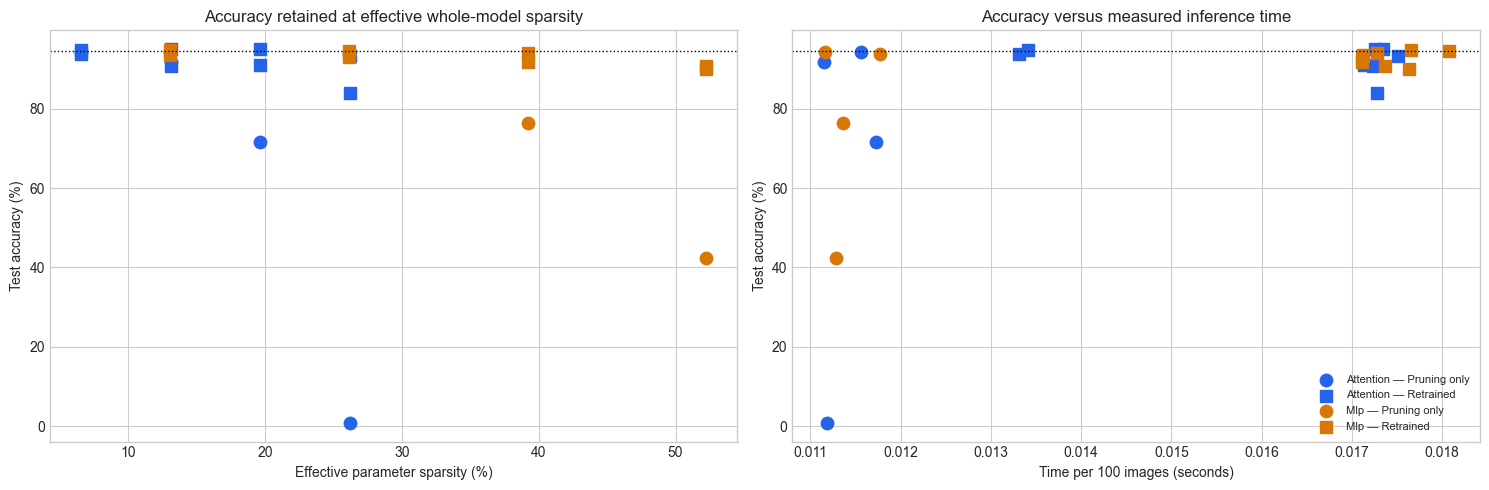

training_seconds  best_epoch  early_stopped
prune_type init_method                                               
attention  original_init           2840.05       72.75           0.25
           random_reinit           2844.18       72.75           0.25
mlp        original_init           2790.31       76.00           0.00
           random_reinit           2794.96       75.25           0.00

In [5]:
# 3. Efficiency context: effective whole-model sparsity and inference time.
plot_data = pd.concat([
    pruned.assign(condition='Pruning only'),
    retrained.assign(condition='Retrained')
])
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for (prune_type, condition), group in plot_data.groupby(['prune_type', 'condition']):
    axes[0].scatter(group['sparsity_pct'], group['accuracy_pct'], color=COLORS[prune_type], marker='o' if condition == 'Pruning only' else 's', s=80, label=f'{prune_type.title()} — {condition}')
axes[0].axhline(dense_accuracy, color='black', linestyle=':', linewidth=1)
axes[0].set(title='Accuracy retained at effective whole-model sparsity', xlabel='Effective parameter sparsity (%)', ylabel='Test accuracy (%)')

for (prune_type, condition), group in plot_data.groupby(['prune_type', 'condition']):
    axes[1].scatter(group['inference_time_100_images_sec'], group['accuracy_pct'], color=COLORS[prune_type], marker='o' if condition == 'Pruning only' else 's', s=80, label=f'{prune_type.title()} — {condition}')
axes[1].axhline(dense_accuracy, color='black', linestyle=':', linewidth=1)
axes[1].set(title='Accuracy versus measured inference time', xlabel='Time per 100 images (seconds)', ylabel='Test accuracy (%)')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Training duration and stopping diagnostics apply to retraining rows only.
retrained.groupby(['prune_type', 'init_method'])[['training_seconds', 'best_epoch', 'early_stopped']].mean().round(2)